![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 01 | EDA and Baseline

*Project 2 — Machine Learning: From Data to Predictions*

**Alex Russell**  
**Dataset:** IBM Telco Customer Churn

This notebook frames the business problem, checks data quality, explores the target and the most relevant feature relationships, fixes the train/test split, and establishes the baseline every real model must beat.

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import RAW, RANDOM_STATE

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

---
## 1. Frame the problem

## Problem framing

The main task is to predict which existing telecom customers are likely to churn so that a **customer retention team can decide who to contact first** with support, service recovery or a relevant retention conversation.

The target is `Churn`, with **Yes** as the positive class.

A **false negative** means we fail to identify a customer who is actually going to leave, so the business loses the chance to intervene. A **false positive** means we contact a customer who would probably have stayed, which uses agent time and potentially some retention budget.

Because missing a genuine churner is the more damaging error, **recall for the churn class is the main metric**. I will also monitor precision and F1 so that improving recall does not simply mean flagging everyone.

A secondary question supports the modelling task: **which existing customer characteristics are most strongly associated with churn?** That helps check whether the model learns patterns that make business sense and later supports interpretation.

---
## 2. Load the raw data

In [2]:
data = pd.read_csv(RAW / "telco_churn.csv")

data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


---
## 3. First look

In [3]:
print("Shape:", data.shape)

print("\nColumns:")
print(data.columns.tolist())

print("\nData types:")
print(data.dtypes)

print("\nFirst 5 rows:")
display(data.head())

Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Each row represents one telecom customer. The target is Churn, which tells us whether that customer left in the last month. There are 7,043 customers and a mixture of numerical and categorical features.

---
## 4. Data quality

In [4]:
# Missing values
print("Missing values:")
print(data.isnull().sum())

# Duplicates
print("\nDuplicate rows:", data.duplicated().sum())

# Check TotalCharges because it is stored as text
print("\nTotalCharges dtype:", data["TotalCharges"].dtype)

# Find blank TotalCharges values
blank_totalcharges = data[data["TotalCharges"].str.strip() == ""]

print("\nBlank TotalCharges rows:", len(blank_totalcharges))
display(
    blank_totalcharges[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

# Check whether those blank values belong to brand-new customers
print("\nTenure values for blank TotalCharges:")
print(blank_totalcharges["tenure"].value_counts())

# Convert TotalCharges to numeric
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"],
    errors="coerce"
)

print("\nMissing values after conversion:")
print(data.isnull().sum())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0

TotalCharges dtype: object

Blank TotalCharges rows: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No



Tenure values for blank TotalCharges:
tenure
0    11
Name: count, dtype: int64

Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


There are 11 blank values in TotalCharges. These belong to customers with a tenure of 0 months, so the missing value has a logical explanation: they have not yet accumulated total charges. TotalCharges was stored as text and has been converted to numeric. I will keep these customers and fill their missing TotalCharges with 0 rather than remove them.

In [5]:
data["TotalCharges"] = data["TotalCharges"].fillna(0)

print(data["TotalCharges"].dtype)
print("Missing TotalCharges:", data["TotalCharges"].isnull().sum())

float64
Missing TotalCharges: 0


---
## 5. Columns that must go

In [6]:
# customerID is just an identifier and should not be used as a feature
data = data.drop(columns=["customerID"])

print("Remaining columns:")
print(data.columns.tolist())

Remaining columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


customerID was removed because it is only a unique identifier for each customer and contains no useful information for predicting churn.  
I found no other columns that clearly contain information unavailable at prediction time, so no further leakage columns need to be removed at this stage.

---
## 6. The target

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Percentages:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


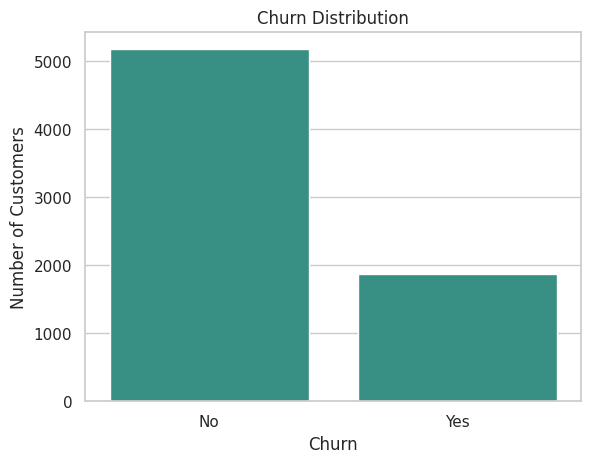

In [7]:
# Count each class
print(data["Churn"].value_counts())

# Show percentages
print("\nPercentages:")
print(data["Churn"].value_counts(normalize=True) * 100)

# Plot the target
sns.countplot(data=data, x="Churn", color="#2A9D8F")
plt.title("Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

The target is imbalanced: around 26.5% of customers churned and 73.5% did not. This means accuracy alone could be misleading because a model predicting No for every customer would already be correct about 73.5% of the time. For this project, recall for churn will therefore be more useful as the main metric, while precision and F1 will also be monitored.

---
## 7. Features against the target

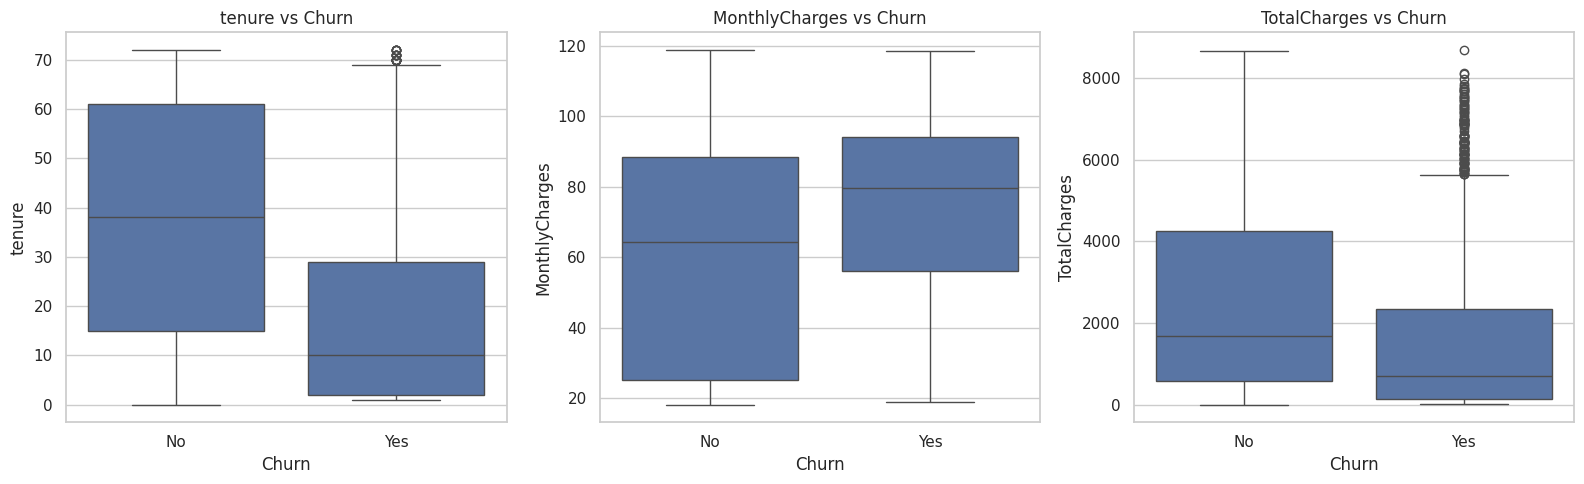

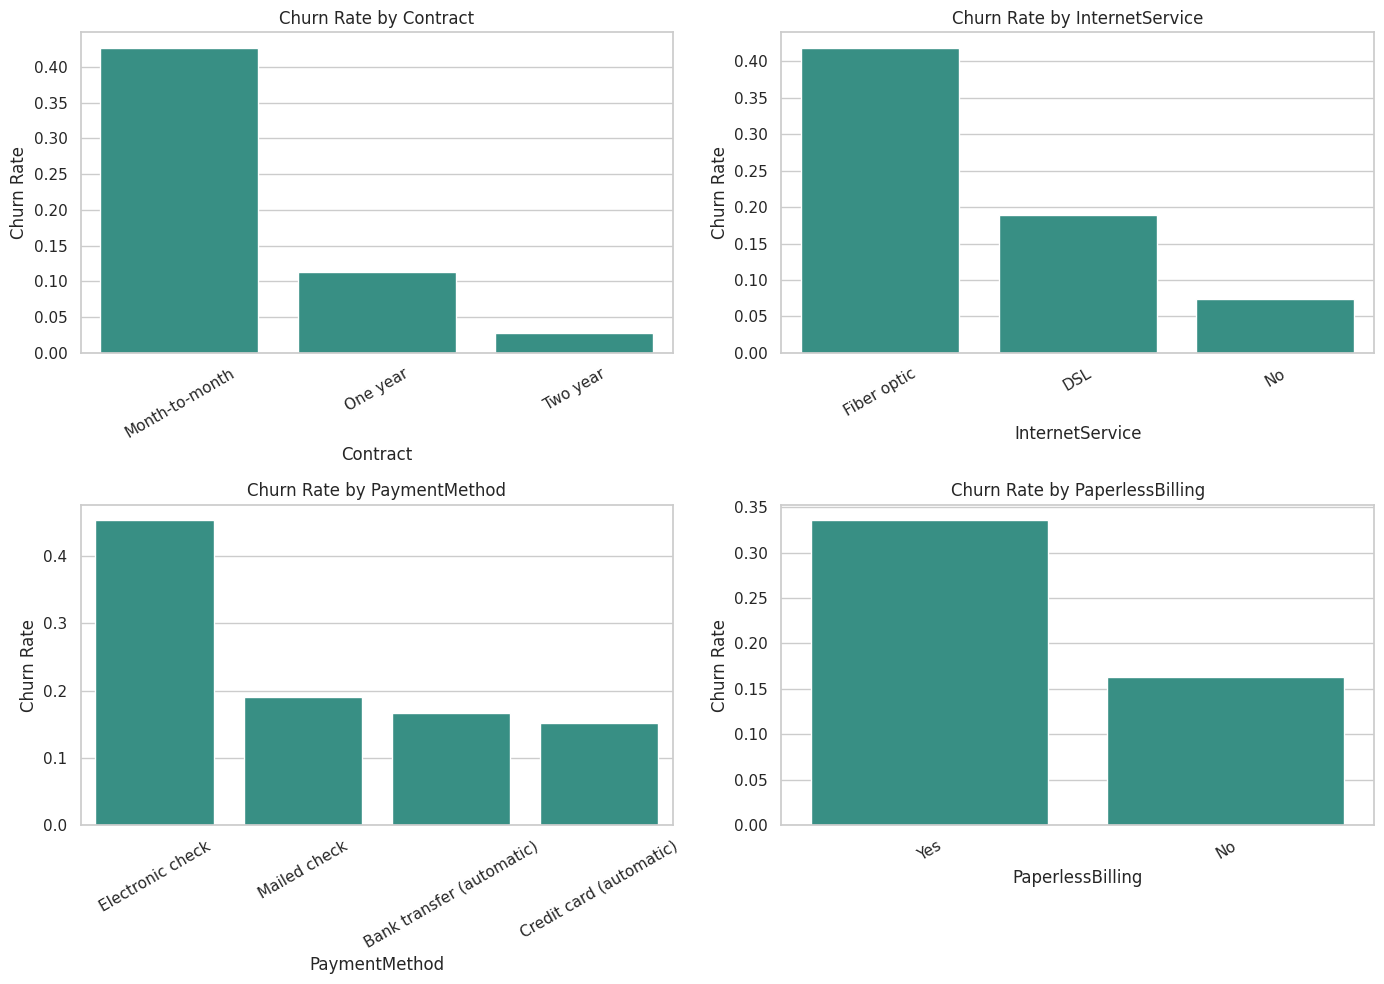

In [8]:
# Create a numeric version of the target just for plotting churn rates
data["Churn_num"] = data["Churn"].map({"No": 0, "Yes": 1})


# -------------------------
# NUMERIC FEATURES VS CHURN
# -------------------------

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, numeric_features):
    sns.boxplot(
        data=data,
        x="Churn",
        y=col,
        ax=ax
    )
    ax.set_title(f"{col} vs Churn")

plt.tight_layout()
plt.show()


# -----------------------------
# CATEGORICAL FEATURES VS CHURN
# -----------------------------

categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "PaperlessBilling"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, col in zip(axes, categorical_features):

    churn_rate = (
        data.groupby(col)["Churn_num"]
        .mean()
        .sort_values(ascending=False)
        .reset_index()
    )

    sns.barplot(
        data=churn_rate,
        x=col,
        y="Churn_num",
        ax=ax,
        color="#2A9D8F"
    )

    ax.set_title(f"Churn Rate by {col}")
    ax.set_ylabel("Churn Rate")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


# Remove temporary numeric target again
data = data.drop(columns=["Churn_num"])

Customers who churn tend to have shorter tenure and higher monthly charges.  
Churn is also noticeably higher among customers with month-to-month contracts, fibre optic internet, electronic check payment, and paperless billing.  
Longer-term contracts are associated with much lower churn, suggesting that contract type and customer tenure may be especially useful predictors.

### Numeric feature relationships

Because the three charge/tenure variables describe related parts of the same customer history, I also checked how strongly they move together. This matters particularly when interpreting Logistic Regression coefficients later.

                tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.248         0.826
MonthlyCharges   0.248           1.000         0.651
TotalCharges     0.826           0.651         1.000


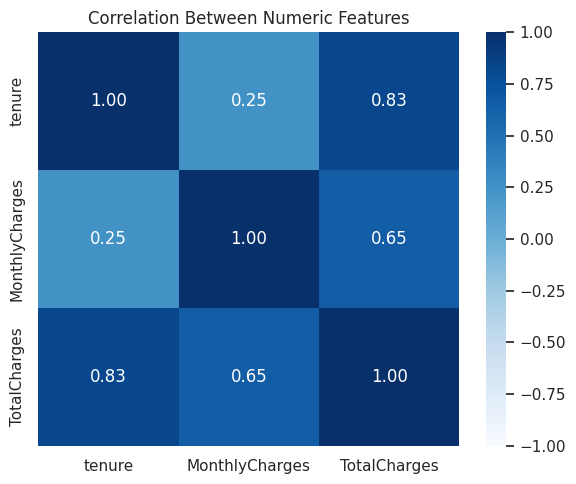

In [9]:
numeric_correlation = data[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].corr()

print(numeric_correlation.round(3))

plt.figure(figsize=(6, 5))
sns.heatmap(
    numeric_correlation,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()

`tenure` and `TotalCharges` are strongly related, which is expected because total charges accumulate over time. I will keep both because they represent different business information, but I will be cautious about treating either Logistic Regression coefficient as an isolated causal effect. This relationship is revisited during interpretation in notebook 03.

---
## 8. Split once

In [10]:
from sklearn.model_selection import train_test_split


# Features and target
X = data.drop(columns=["Churn"])
y = data["Churn"]

# Split once - stratify keeps the churn proportion similar
# in both train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True))

print("\nTest target proportions:")
print(y_test.value_counts(normalize=True))

Training shape: (5634, 19)
Test shape: (1409, 19)

Training target proportions:
Churn
No     0.734647
Yes    0.265353
Name: proportion, dtype: float64

Test target proportions:
Churn
No     0.734564
Yes    0.265436
Name: proportion, dtype: float64


The data was split once into 80% training data and 20% test data using a fixed random state for reproducibility. Because this is a classification problem, I used stratify=y so that the proportion of churners is similar in both sets. From this point onwards, model development and cross-validation will use only the training data. The test set will remain untouched until the final evaluation.

---
## 9. Baseline

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import make_scorer, recall_score

# Use these exact folds for every model later
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Our main metric: recall for customers who actually churn
recall_scorer = make_scorer(
    recall_score,
    pos_label="Yes"
)

# Baseline model: always predicts the most common class
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

# Cross-validated recall on TRAINING DATA ONLY
baseline_scores = cross_val_score(
    dummy_model,
    X_train,
    y_train,
    cv=cv,
    scoring=recall_scorer
)

print("Recall for each fold:", baseline_scores)
print("Mean baseline recall:", baseline_scores.mean())
print("Standard deviation:", baseline_scores.std())

Recall for each fold: [0. 0. 0. 0. 0.]
Mean baseline recall: 0.0
Standard deviation: 0.0


The baseline DummyClassifier predicts the majority class for every customer. Because most customers do not churn, it predicts No for everyone and therefore has a recall of 0 for the churn class. This gives us a basic benchmark: our real models must identify actual churners substantially better than this.

---
## 10. Handoff to modelling

The fixed training set, the recall scorer and the five stratified folds established here are reused in notebook 02. Numeric features will be imputed and scaled; categorical features will be imputed and one-hot encoded inside the modelling pipeline so that preprocessing is refitted separately in every cross-validation fold.